<a href="https://colab.research.google.com/github/EnesKok20/cepte-vet/blob/main/04_temizlik_ve_bolme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!pip -q install imagehash

import os, glob, shutil, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import imagehash

ANA = '/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik'
RAW = ANA + '/raw'
DATA = '/content/data'
UZANTILAR = ('.png', '.jpg', '.jpeg', '.webp', '.bmp')
random.seed(42)

Mounted at /content/drive


In [3]:
import zipfile

!mkdir -p {DATA}/mendeley {DATA}/kaggle
!unzip -q -o "{RAW}/Lumpy Skin Images Dataset.zip" -d {DATA}/mendeley
for z in glob.glob(f'{DATA}/mendeley/**/*.zip', recursive=True):
    zipfile.ZipFile(z).extractall(f'{DATA}/mendeley')
    os.remove(z)

!unzip -q -o "{RAW}/archive.zip" -d {DATA}/kaggle
!find {DATA} -maxdepth 4 -type d

/content/data
/content/data/kaggle
/content/data/kaggle/Cows datasets
/content/data/kaggle/Cows datasets/foot-and-mouth
/content/data/kaggle/Cows datasets/healthy
/content/data/kaggle/Cows datasets/lumpy
/content/data/mendeley
/content/data/mendeley/Lumpy Skin
/content/data/mendeley/Normal Skin
/content/data/mendeley/Lumpy Skin Images Dataset


In [4]:
kayitlar = []

def ekle(kaynak, klasor_deseni, etiket):
    for yol in glob.glob(klasor_deseni, recursive=True):
        if yol.lower().endswith(UZANTILAR):
            kayitlar.append({'yol': yol, 'kaynak': kaynak, 'etiket': etiket})

ekle('mendeley', f'{DATA}/mendeley/**/Normal Skin/*', 'healthy')
ekle('mendeley', f'{DATA}/mendeley/**/Lumpy Skin/*',  'lumpy')
ekle('kaggle',   f'{DATA}/kaggle/**/healthy/*',       'healthy')
ekle('kaggle',   f'{DATA}/kaggle/**/lumpy/*',         'lumpy')

df = pd.DataFrame(kayitlar)
print(df.groupby(['kaynak', 'etiket']).size())
print('Toplam:', len(df))

kaynak    etiket 
kaggle    healthy    1291
          lumpy      1207
mendeley  healthy     700
          lumpy       324
dtype: int64
Toplam: 3522


In [5]:
from tqdm.auto import tqdm

h_normal, h_ayna, boyut, gecerli = [], [], [], []
for yol in tqdm(df['yol']):
    try:
        img = Image.open(yol).convert('RGB')
    except Exception as e:
        gecerli.append(False); h_normal.append(None); h_ayna.append(None); boyut.append(0)
        continue
    gecerli.append(True)
    boyut.append(img.size[0] * img.size[1])
    h_normal.append(imagehash.phash(img).hash.flatten())
    h_ayna.append(imagehash.phash(img.transpose(Image.FLIP_LEFT_RIGHT)).hash.flatten())

df['boyut'] = boyut
print('Açılamayan dosya:', (~np.array(gecerli)).sum())
gecerli = np.array(gecerli)
df = df[gecerli].reset_index(drop=True)
H  = np.array([h for h, g in zip(h_normal, gecerli) if g], dtype=np.float32)
HA = np.array([h for h, g in zip(h_ayna,  gecerli) if g], dtype=np.float32)

  0%|          | 0/3522 [00:00<?, ?it/s]

Açılamayan dosya: 0


In [6]:
def hamming(A, B):
    return A @ (1 - B).T + (1 - A) @ B.T

D = np.minimum(hamming(H, H), hamming(H, HA))
np.fill_diagonal(D, 99)
print('Matris boyutu:', D.shape)

ESIK = 6
for e in [0, 2, 4, 6, 8, 10]:
    print(f'mesafe <= {e:2d}: {int((D <= e).sum() // 2)} çift')

Matris boyutu: (3522, 3522)
mesafe <=  0: 400 çift
mesafe <=  2: 474 çift
mesafe <=  4: 488 çift
mesafe <=  6: 586 çift
mesafe <=  8: 710 çift
mesafe <= 10: 830 çift


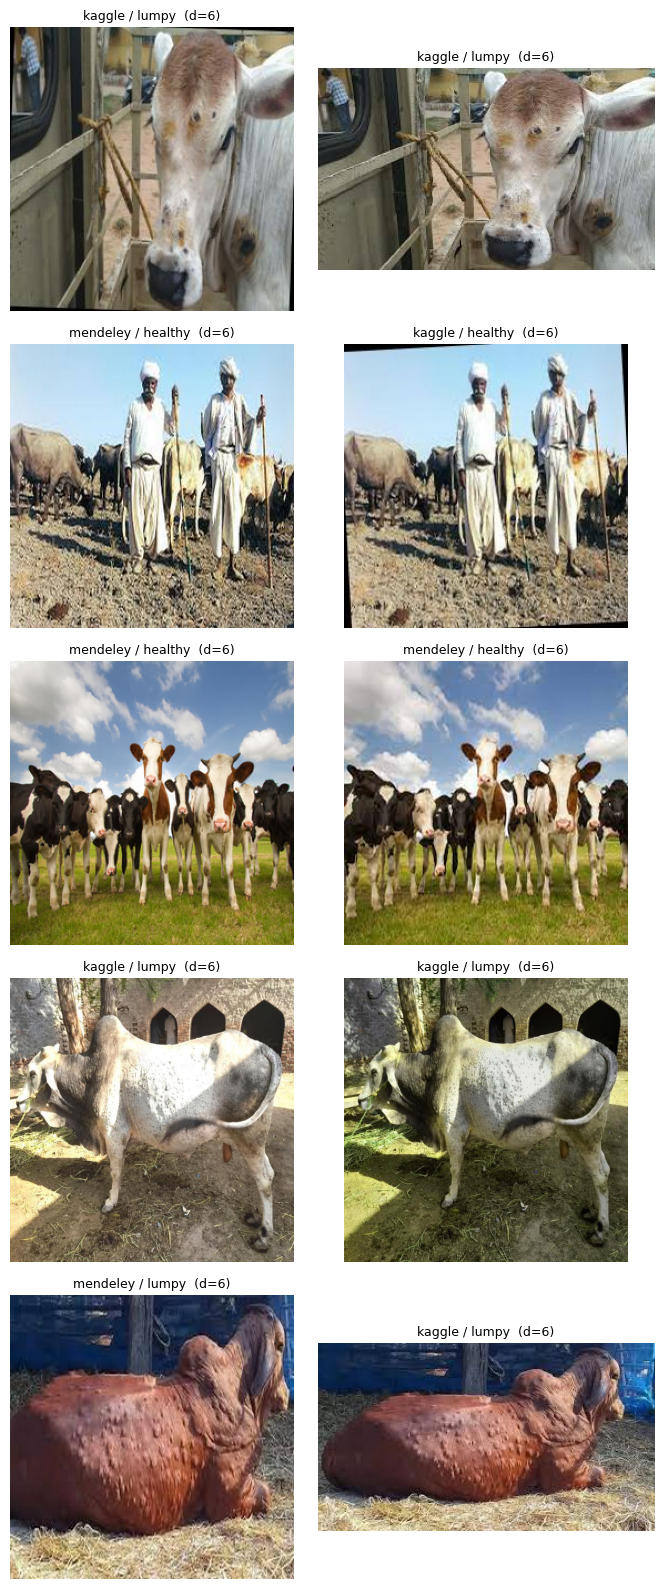

In [7]:
i_idx, j_idx = np.where(np.triu((D >= ESIK - 1) & (D <= ESIK)))
ornek = random.sample(list(zip(i_idx, j_idx)), min(5, len(i_idx)))
fig, eks = plt.subplots(len(ornek), 2, figsize=(7, 3.2 * len(ornek)), squeeze=False)
for s, (i, j) in enumerate(ornek):
    for k, idx in enumerate([i, j]):
        r = df.iloc[idx]
        eks[s, k].imshow(Image.open(r['yol']).convert('RGB'))
        eks[s, k].set_title(f"{r['kaynak']} / {r['etiket']}  (d={int(D[i, j])})", fontsize=9)
        eks[s, k].axis('off')
plt.tight_layout(); plt.show()

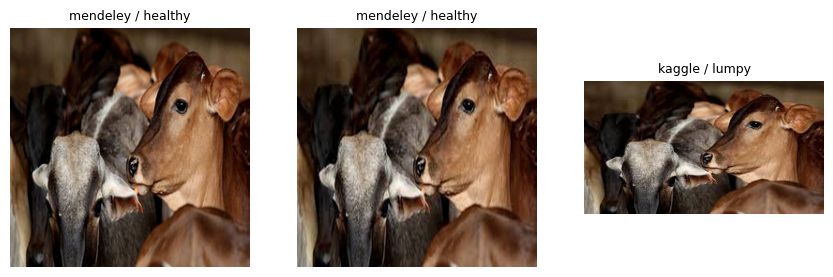

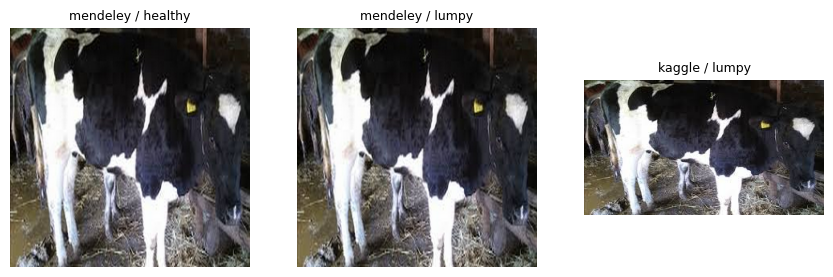

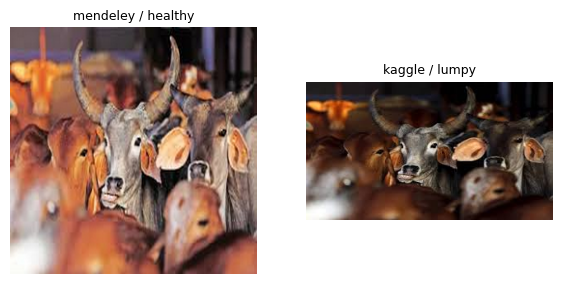

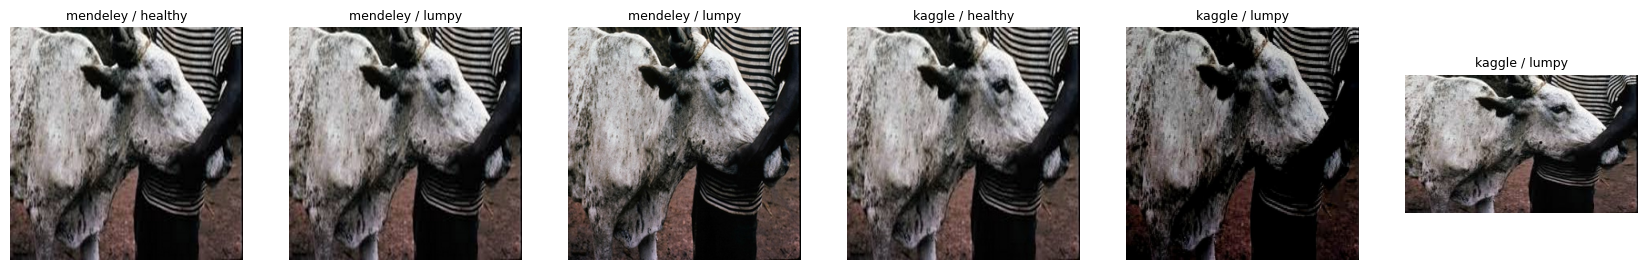

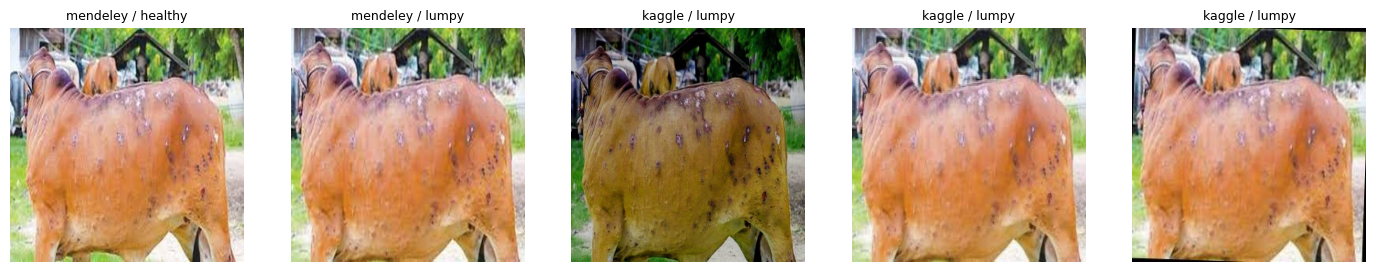

In [12]:
for g in list(cakisan)[:5]:
    grup_df = df[df['grup'] == g]
    fig, eks = plt.subplots(1, len(grup_df), figsize=(3.5 * len(grup_df), 3.5), squeeze=False)
    for ax, (_, r) in zip(eks[0], grup_df.iterrows()):
        ax.imshow(Image.open(r['yol']).convert('RGB'))
        ax.set_title(f"{r['kaynak']} / {r['etiket']}", fontsize=9)
        ax.axis('off')
    plt.show()

In [13]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

n_grup, grup = connected_components(csr_matrix(D <= ESIK), directed=False)
df['grup'] = grup
print('Görüntü sayısı:', len(df), '| benzersiz grup:', n_grup)

kaynak_sayisi = df.groupby('grup')['kaynak'].nunique()
print('Mendeley ile Kaggle arasında ortak grup:', int((kaynak_sayisi > 1).sum()))

etiket_sayisi = df.groupby('grup')['etiket'].nunique()
cakisan = etiket_sayisi[etiket_sayisi > 1].index
print('Etiketi çelişen grup:', len(cakisan))

Görüntü sayısı: 3522 | benzersiz grup: 3064
Mendeley ile Kaggle arasında ortak grup: 286
Etiketi çelişen grup: 10


In [14]:
temiz = df[~df['grup'].isin(cakisan)]
temiz = temiz.sort_values('boyut', ascending=False).drop_duplicates('grup').reset_index(drop=True)
print(temiz.groupby(['etiket', 'kaynak']).size())
print('Temiz toplam:', len(temiz), '| atılan:', len(df) - len(temiz))

etiket   kaynak  
healthy  kaggle      1240
         mendeley     597
lumpy    kaggle      1078
         mendeley     139
dtype: int64
Temiz toplam: 3054 | atılan: 468


In [15]:
from sklearn.model_selection import train_test_split

train, gecici = train_test_split(temiz, test_size=0.30, stratify=temiz['etiket'], random_state=42)
val, test     = train_test_split(gecici, test_size=0.50, stratify=gecici['etiket'], random_state=42)
train, val, test = train.assign(bolum='train'), val.assign(bolum='val'), test.assign(bolum='test')
son = pd.concat([train, val, test]).reset_index(drop=True)
print(pd.crosstab(son['bolum'], son['etiket'], margins=True))

etiket  healthy  lumpy   All
bolum                       
test        276    183   459
train      1285    852  2137
val         276    182   458
All        1837   1217  3054


In [16]:
HEDEF = f'{DATA}/cattle_cls'
shutil.rmtree(HEDEF, ignore_errors=True)
yeni_adlar = []
for i, r in son.iterrows():
    klasor = f"{HEDEF}/{r['bolum']}/{r['etiket']}"
    os.makedirs(klasor, exist_ok=True)
    ad = f"{r['kaynak']}_{i:05d}{os.path.splitext(r['yol'])[1].lower()}"
    shutil.copy(r['yol'], f'{klasor}/{ad}')
    yeni_adlar.append(ad)
son['yeni_ad'] = yeni_adlar
son['yol'] = son['yol'].str.replace(DATA + '/', '', regex=False)

!find {HEDEF} -type f | cut -d/ -f5,6 | sort | uniq -c

os.makedirs(f'{ANA}/hazir', exist_ok=True)
son.drop(columns=['boyut']).to_csv(f'{ANA}/hazir/manifest.csv', index=False)
!cd {DATA} && zip -q -r cattle_cls.zip cattle_cls && cp cattle_cls.zip "{ANA}/hazir/"
!ls -lh "{ANA}/hazir"

    276 test/healthy
    183 test/lumpy
   1285 train/healthy
    852 train/lumpy
    276 val/healthy
    182 val/lumpy
total 197M
-rw------- 1 root root 197M Nov  2 08:57 cattle_cls.zip
-rw------- 1 root root 307K Nov  2 08:57 manifest.csv
